In [ ]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))
print("All libraries imported successfully!")


TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
All libraries imported successfully!


In [ ]:

BASE_PATH = "/content"

# Extract uploaded ZIP files
for file_name in os.listdir(BASE_PATH):
    if file_name.lower().endswith(".zip"):
        zip_path = os.path.join(BASE_PATH, file_name)

        print("Extracting:", file_name)

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(BASE_PATH)

# Flower class names
class_names = [
    "daisy",
    "dandelion",
    "rose",
    "sunflower",
    "tulip"
]

# Find dataset directory
DATA_DIR = None

for root, dirs, files in os.walk(BASE_PATH):

    folder_map = {
        folder.lower(): folder
        for folder in dirs
    }

    if all(name in folder_map for name in class_names):
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset folders not found. "
        "Please check whether all five flower folders are uploaded."
    )

print("Dataset found successfully!")
print("Dataset path:", DATA_DIR)


Extracting: archive.zip
Dataset found successfully!
Dataset path: /content/flowers


In [ ]:

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []
labels = []

for label, class_name in enumerate(class_names):

    # Find actual folder name, ignoring uppercase/lowercase
    actual_folder = next(
        folder for folder in os.listdir(DATA_DIR)
        if folder.lower() == class_name
        and os.path.isdir(os.path.join(DATA_DIR, folder))
    )

    class_folder = os.path.join(DATA_DIR, actual_folder)

    files = [
        os.path.join(class_folder, file)
        for file in os.listdir(class_folder)
        if file.lower().endswith(image_extensions)
    ]

    print(class_name, ":", len(files), "images")

    if len(files) == 0:
        raise ValueError(f"No images found in {class_name} folder!")

    image_paths.extend(files)
    labels.extend([label] * len(files))

image_paths = np.array(image_paths)
labels = np.array(labels, dtype=np.int32)

print("\nTotal Images:", len(image_paths))
print("Total Classes:", len(class_names))


daisy : 764 images
dandelion : 1052 images
rose : 784 images
sunflower : 733 images
tulip : 984 images

Total Images: 4317
Total Classes: 5


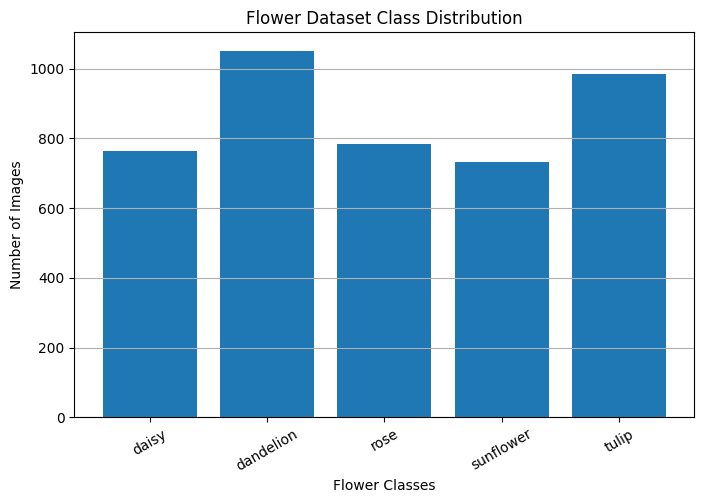

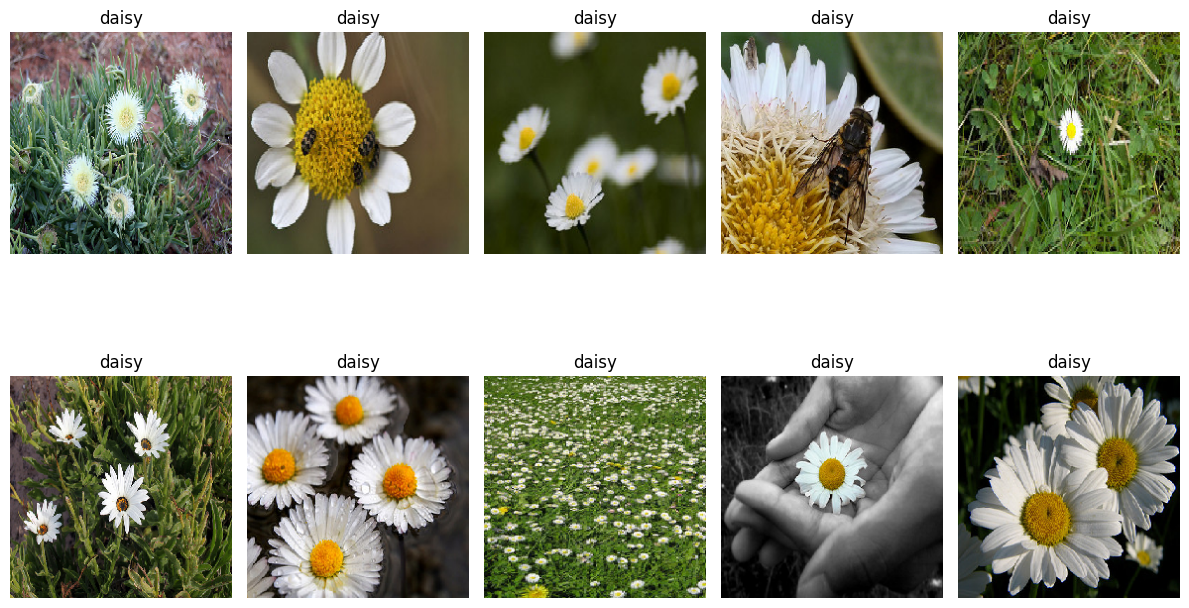

In [ ]:

class_counts = [
    np.sum(labels == i)
    for i in range(len(class_names))
]

plt.figure(figsize=(8, 5))
plt.bar(class_names, class_counts)

plt.title("Flower Dataset Class Distribution")
plt.xlabel("Flower Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()


# Display sample images
plt.figure(figsize=(12, 8))

for i in range(min(10, len(image_paths))):

    plt.subplot(2, 5, i + 1)

    img = tf.keras.utils.load_img(
        image_paths[i],
        target_size=(224, 224)
    )

    plt.imshow(img)
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

print("\nSplit completed successfully!")


Training Images: 3021
Validation Images: 648
Testing Images: 648

Split completed successfully!


In [ ]:

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(
    X_train, y_train, training=True
)

val_ds = create_dataset(
    X_val, y_val
)

test_ds = create_dataset(
    X_test, y_test
)

print("Training, validation and test datasets created!")


Training, validation and test datasets created!


In [ ]:

data_augmentation = models.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.1),

    layers.RandomContrast(0.1)

], name="data_augmentation")

print("Data augmentation created successfully!")


Data augmentation created successfully!


In [ ]:

NUM_CLASSES = len(class_names)

def create_custom_cnn():

    model = models.Sequential([

        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        # Image normalization
        layers.Rescaling(1.0 / 255),

        # Data augmentation
        data_augmentation,

        # Block 1
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Block 3
        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Block 4
        layers.Conv2D(256, (3, 3), padding="same"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Fully connected layers
        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),

        layers.Dropout(0.5),

        # Output layer
        layers.Dense(NUM_CLASSES, activation="softmax")

    ])

    return model


# Create model
model = create_custom_cnn()

# Display architecture
model.summary()

print("Custom CNN model created successfully!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 457,413 (1.74 MB)

 Trainable params: 456,453 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

Custom CNN model created successfully!


In [ ]:

LEARNING_RATE = 0.001
EPOCHS = 30

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


In [ ]:

RESULTS_DIR = "/content/submission3_results"

os.makedirs(RESULTS_DIR, exist_ok=True)


early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=5,

    min_delta=0.001,

    restore_best_weights=True,

    start_from_epoch=5,

    verbose=1
)


checkpoint = ModelCheckpoint(

    filepath=os.path.join(
        RESULTS_DIR,
        "best_custom_cnn.keras"
    ),

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=0.00001,

    verbose=1
)


callbacks = [
    early_stopping,
    checkpoint,
    reduce_lr
]

print("All callbacks created successfully!")


All callbacks created successfully!


In [ ]:

# Check required variables
assert model is not None, "Model is not created!"
assert train_ds is not None, "Training dataset is missing!"
assert val_ds is not None, "Validation dataset is missing!"
assert callbacks is not None, "Callbacks are missing!"

print("Starting Custom CNN training...")

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1

)

print("\nTraining completed successfully!")

print(
    "Total epochs trained:",
    len(history.history["loss"])
)


Starting Custom CNN training...
Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.4044 - loss: 1.4678
Epoch 1: val_loss improved from None to 1.95152, saving model to /content/submission3_results/best_custom_cnn.keras

Epoch 1: finished saving model to /content/submission3_results/best_custom_cnn.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 27s 165ms/step - accuracy: 0.4869 - loss: 1.2871 - val_accuracy: 0.2438 - val_loss: 1.9515 - learning_rate: 0.0010
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.5494 - loss: 1.0987
Epoch 2: val_loss improved from 1.95152 to 1.89931, saving model to /content/submission3_results/best_custom_cnn.keras

Epoch 2: finished saving model to /content/submission3_results/best_custom_cnn.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 136ms/step - accuracy: 0.5442 - loss: 1.1075 - val_accuracy: 0.2593 - val_loss: 1.8993 - learning_rate: 0.0010
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.5906 - loss: 1.0395
Epoch 3: val_loss d

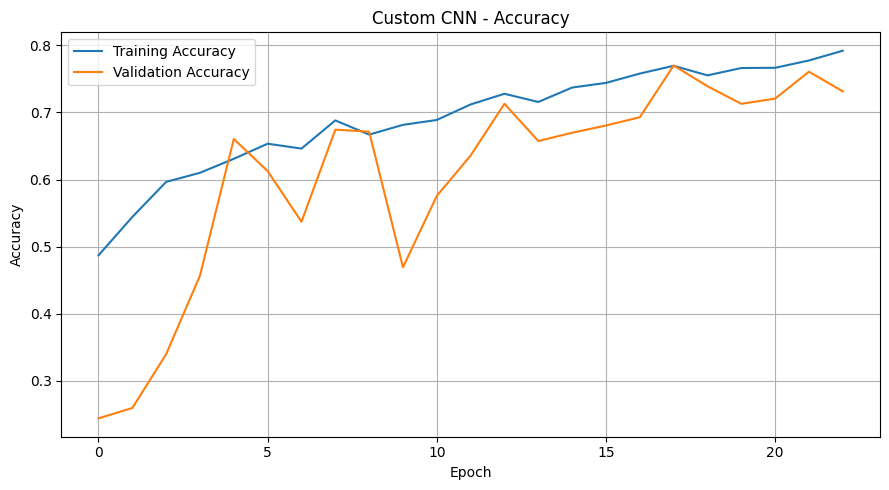

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "accuracy_curve.png"),
    dpi=150
)

plt.show()


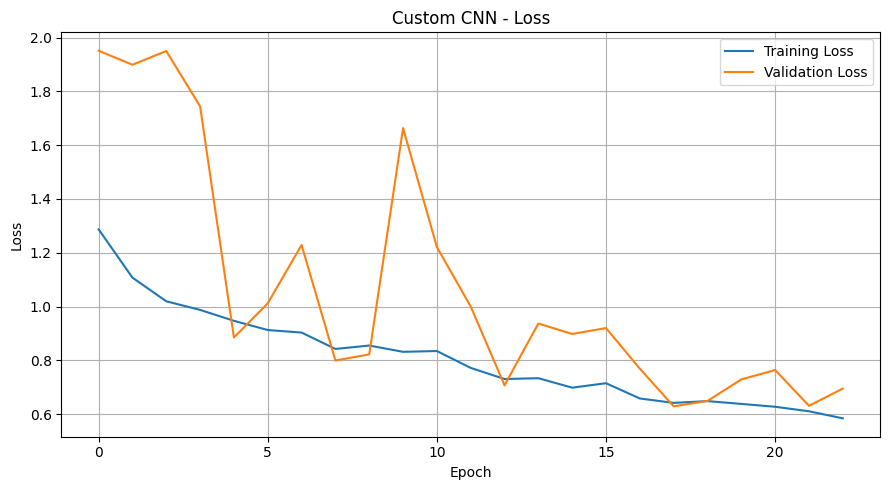

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "loss_curve.png"),
    dpi=150
)

plt.show()


In [ ]:

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("CUSTOM CNN TEST RESULTS")
print("-----------------------")

print("Test Loss:", round(test_loss, 4))

print("Test Accuracy:", round(test_accuracy, 4))

print(
    "Test Accuracy Percentage:",
    round(test_accuracy * 100, 2),
    "%"
)


21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.7438 - loss: 0.7273
CUSTOM CNN TEST RESULTS
-----------------------
Test Loss: 0.7273
Test Accuracy: 0.7438
Test Accuracy Percentage: 74.38 %


In [ ]:

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Predicted probabilities
y_pred_prob = model.predict(test_ds)

# Predicted class
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
)

print("CUSTOM CNN CLASSIFICATION REPORT")
print("--------------------------------")
print(report)

# Save report
report_path = os.path.join(
    RESULTS_DIR,
    "classification_report.txt"
)

with open(report_path, "w") as file:
    file.write(report)

print("Classification report saved!")


21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step
CUSTOM CNN CLASSIFICATION REPORT
--------------------------------
              precision    recall  f1-score   support

       daisy       0.73      0.73      0.73       115
   dandelion       0.79      0.79      0.79       158
        rose       0.61      0.60      0.61       117
   sunflower       0.78      0.92      0.84       110
       tulip       0.78      0.69      0.73       148

    accuracy                           0.74       648
   macro avg       0.74      0.75      0.74       648
weighted avg       0.74      0.74      0.74       648

Classification report saved!


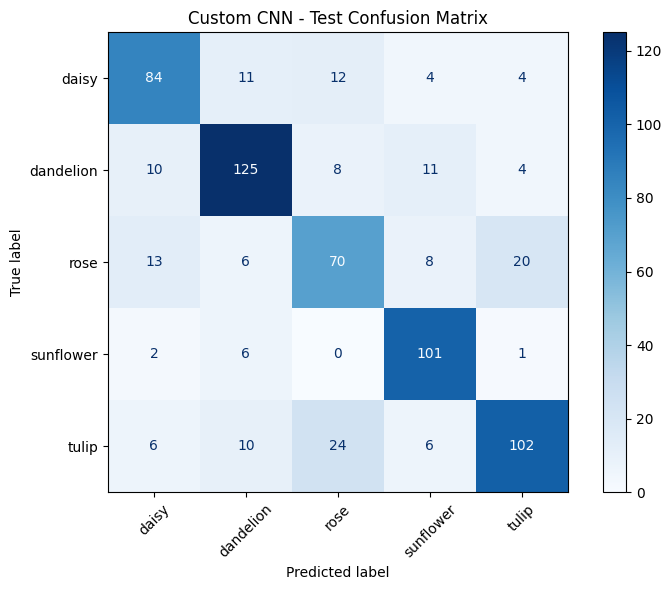

Confusion matrix saved!


In [ ]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax
)

plt.title("Custom CNN - Test Confusion Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "confusion_matrix.png"
    ),
    dpi=150
)

plt.show()

print("Confusion matrix saved!")


In [ ]:

# Save training history
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "training_history.csv"
    ),
    index=False
)

# Save final trained model
model.save(
    os.path.join(
        RESULTS_DIR,
        "custom_cnn_final.keras"
    )
)

# Create final result table
final_results = pd.DataFrame([{

    "Model": "Custom CNN",

    "Test Accuracy": test_accuracy,

    "Test Loss": test_loss,

    "Epochs Trained": len(history.history["loss"]),

    "Optimizer": "Adam",

    "Learning Rate": LEARNING_RATE,

    "Batch Size": BATCH_SIZE

}])

display(final_results)

final_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "final_results.csv"
    ),
    index=False
)

print("All results saved successfully!")


,Model,Test Accuracy,Test Loss,Epochs Trained,Optimizer,Learning Rate,Batch Size
0,Custom CNN,0.743827,0.72727,23,Adam,0.001,32


All results saved successfully!


In [ ]:

print("SUBMISSION 3: CUSTOM CNN FROM SCRATCH")
print("=====================================")

print("Model: Custom CNN")

print("Number of Classes:", NUM_CLASSES)

print("Training Images:", len(X_train))

print("Validation Images:", len(X_val))

print("Testing Images:", len(X_test))

print("Epochs Trained:", len(history.history["loss"]))

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("Test Loss:", round(test_loss, 4))

print("\nGenerated Result Files:")

for file_name in sorted(os.listdir(RESULTS_DIR)):
    print("-", file_name)


SUBMISSION 3: CUSTOM CNN FROM SCRATCH
Model: Custom CNN
Number of Classes: 5
Training Images: 3021
Validation Images: 648
Testing Images: 648
Epochs Trained: 23
Test Accuracy: 74.38 %
Test Loss: 0.7273

Generated Result Files:
- accuracy_curve.png
- best_custom_cnn.keras
- classification_report.txt
- confusion_matrix.png
- custom_cnn_final.keras
- final_results.csv
- loss_curve.png
- training_history.csv
